# Análisis del sector automotriz (2016–hoy)

**Pregunta central:** ¿Qué armadoras han creado más valor en la última década y cuáles resistieron mejor la crisis de semiconductores?

Empresas: Toyota, Volkswagen, BMW, Mercedes-Benz, Stellantis, GM, Ford y Tesla.

> Antes de correr este notebook ejecuta `python src/descarga_datos.py` desde la raíz del repo.

In [12]:
import sys
sys.path.append("../src")

import pandas as pd
import analisis as an
from config import DATA_RAW, DATA_PROCESSED

pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Carga y limpieza de datos

In [3]:
precios = pd.read_csv(DATA_RAW / "precios.csv", index_col=0, parse_dates=True)
precios = an.limpiar_precios(precios)

print(f"Periodo: {precios.index.min().date()} → {precios.index.max().date()}")
print(f"Datos faltantes por empresa:\n{precios.isna().sum()}")
precios.tail()

Periodo: 2016-01-04 → 2026-09-29
Datos faltantes por empresa:
Toyota            0
Volkswagen        0
BMW               0
Mercedes-Benz     0
Stellantis        0
General Motors    0
Ford              0
Tesla             0
dtype: int64


,Toyota,Volkswagen,BMW,Mercedes-Benz,Stellantis,General Motors,Ford,Tesla
Date,,,,,,,,
2026-09-23,"2,974.36",72.90,57.88,42.10,4.62,83.77,12.94,380.12
2026-09-24,"2,919.29",70.82,56.46,41.24,4.47,80.57,12.60,377.94
2026-09-25,"2,939.45",71.72,55.72,41.28,4.60,82.63,12.71,372.11
2026-09-28,"2,936.50",70.88,55.18,41.43,4.62,80.64,12.38,357.45
2026-09-29,"2,881.50",71.24,55.00,40.76,4.53,80.54,12.38,354.24


Stellantis nace en 2021 (fusión FCA + PSA), por eso su serie empieza después. Las bolsas de Tokio, Frankfurt y Nueva York tienen feriados distintos, así que rellenamos los huecos con el último precio conocido.

## 2. Evolución del precio

Normalizamos a base 100 para comparar empresas que cotizan en yenes, euros y dólares.

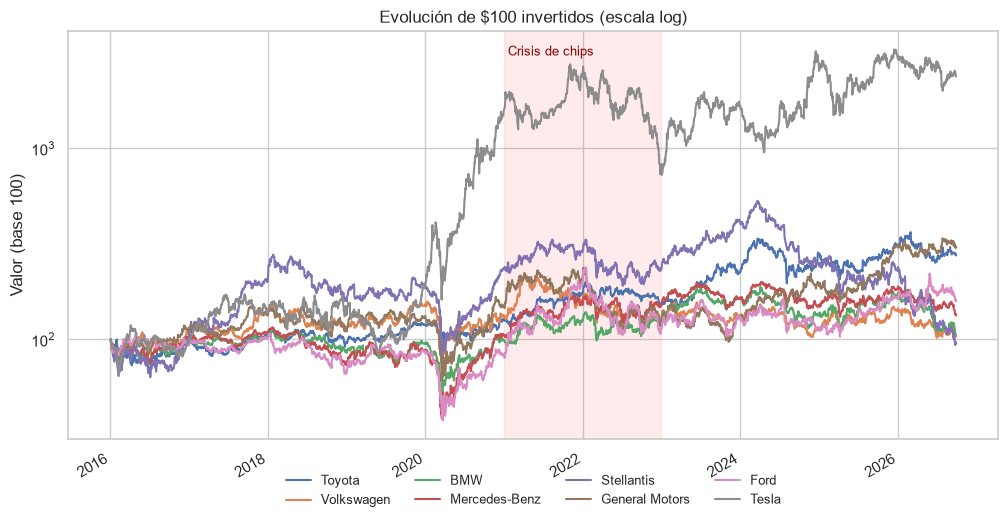

In [4]:
norm = an.normalizar(precios)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
norm.to_csv(DATA_PROCESSED / "precios_normalizados.csv")
an.graficar_normalizado(norm);

**Observaciones:** _escribe aquí lo que ves en la gráfica._

## 3. Riesgo vs. rendimiento

In [5]:
tabla = an.metricas_riesgo_rendimiento(precios)
tabla

,rend_anual_%,volatilidad_%,max_caida_%,rend/riesgo
Tesla,34.34,57.45,-73.63,0.60
Toyota,9.88,27.29,-41.67,0.36
General Motors,10.86,35.77,-59.96,0.30
Ford,4.40,36.30,-64.77,0.12
Mercedes-Benz,2.73,30.04,-66.64,0.09
BMW,0.59,27.60,-56.97,0.02
Volkswagen,0.37,32.05,-53.00,0.01
Stellantis,-0.48,41.32,-82.32,-0.01


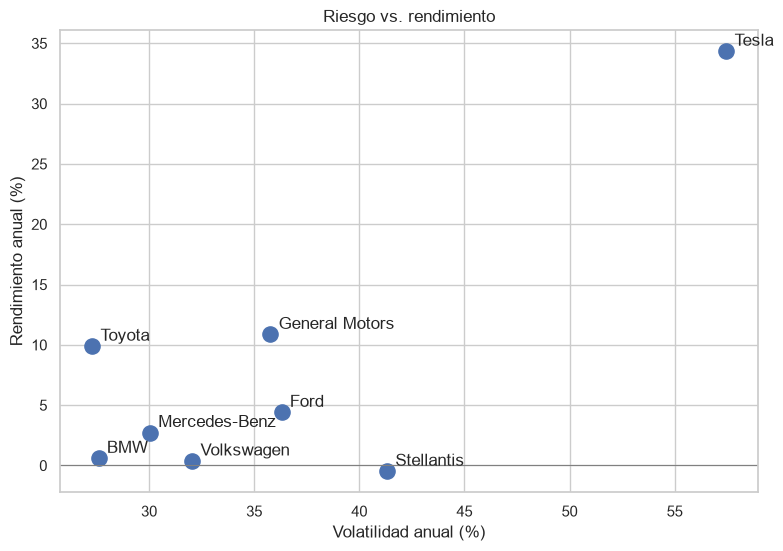

In [6]:
an.graficar_riesgo_rendimiento(tabla);

**Observaciones:** _¿quién da más rendimiento por unidad de riesgo?_

## 4. Impacto de la crisis de chips (2021–2022)

In [7]:
crisis = an.impacto_crisis_chips(precios)
crisis

,caida_%,fecha_pico,fecha_valle,dias_para_recuperar
Tesla,-73.40,2021-11-04,2022-12-27,715
Ford,-55.60,2022-01-14,2022-07-06,Aún no
General Motors,-53.00,2022-01-04,2022-07-11,1198
Volkswagen,-47.20,2021-04-06,2022-07-06,Aún no
Stellantis,-42.70,2021-08-13,2022-07-06,372
BMW,-29.00,2022-01-14,2022-03-07,311
Mercedes-Benz,-28.10,2022-02-17,2022-07-06,211
Toyota,-25.30,2022-01-18,2022-03-08,464


**Observaciones:** _¿quién cayó más y quién se recuperó más rápido?_

## 5. ¿Se mueven juntas?

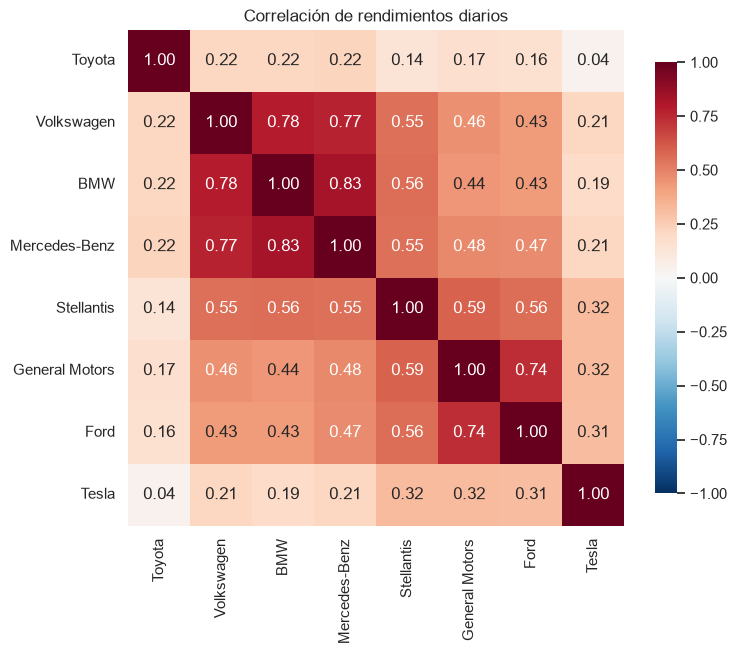

In [8]:
an.graficar_correlacion(precios);

**Observaciones:** _¿las alemanas se correlacionan más entre sí que con las de EE. UU.?_

## 6. Rentabilidad e innovación

Los márgenes y la intensidad de I+D son porcentajes, así que se pueden comparar sin convertir monedas.

In [9]:
fin = pd.read_csv(DATA_RAW / "financieros.csv")
mg = an.margenes(fin)
mg[["empresa", "anio", "margen_operativo_%", "margen_neto_%", "id_sobre_ingresos_%"]]

,empresa,anio,margen_operativo_%,margen_neto_%,id_sobre_ingresos_%
0,BMW,2022,9.96,12.58,NaN
1,BMW,2023,11.88,7.26,NaN
2,BMW,2024,8.00,5.12,NaN
3,BMW,2025,7.48,5.47,NaN
4,Ford,2021,NaN,NaN,NaN
5,Ford,2022,3.97,-1.25,NaN
6,Ford,2023,3.10,2.47,NaN
7,Ford,2024,2.82,3.18,NaN
8,Ford,2025,-4.90,-4.37,NaN
9,General Motors,2022,6.58,6.34,NaN


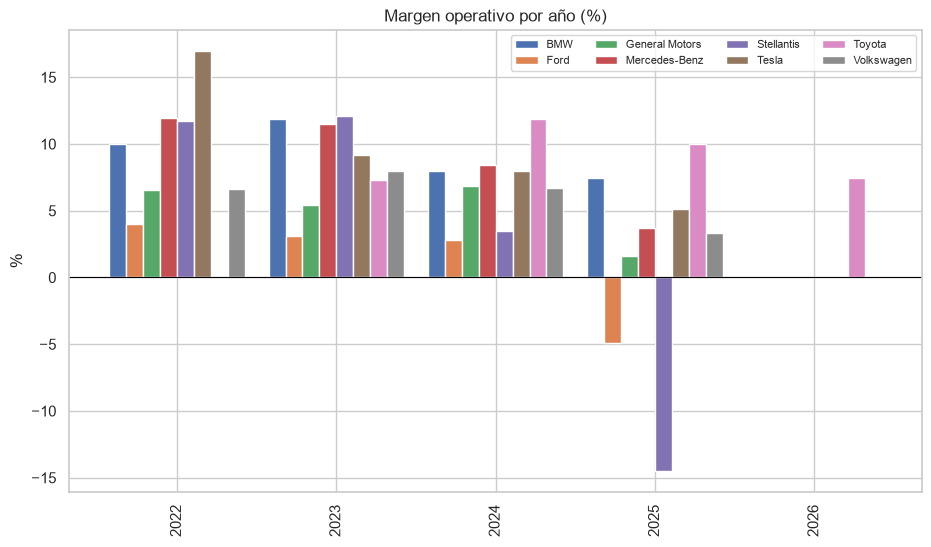

In [10]:
an.graficar_margenes(mg);

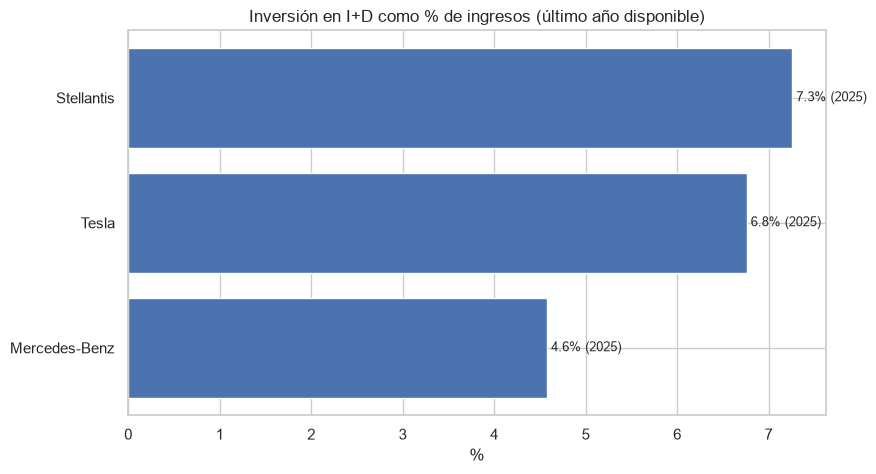

In [11]:
an.graficar_id(mg);

**Observaciones:** _¿más I+D se traduce en mejor desempeño?_

## 7. Conclusiones

1. _…_
2. _…_
3. _…_

**Limitaciones:** los precios están en monedas distintas (se comparan rendimientos, no niveles); yfinance solo entrega ~4 años de estados financieros; algunas empresas no reportan I+D como partida separada.